In [13]:
import pandas as pd
import re
from urllib.parse import urlparse
import matplotlib.pyplot as plt

In [14]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

real["Category"] = "Real"
fake["Category"] = "Fake"

In [15]:
news = pd.concat([real, fake], ignore_index=True)

In [16]:
news["title"] = news["title"].fillna("")
news["text"] = news["text"].fillna("")

In [17]:
news["Full_Text"] = news["title"] + " " + news["text"]

news[["Category", "title", "text"]].head()

,Category,title,text
0,Real,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...
1,Real,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...
2,Real,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...
3,Real,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...
4,Real,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...


In [18]:
# Extract external URLs
news["URLs"] = news["Full_Text"].str.findall(
    r'https?://[^\s<>"\']+'
)

news["URL_Count"] = news["URLs"].str.len()

news[["Category", "title", "URLs", "URL_Count"]].head(10)

,Category,title,URLs,URL_Count
0,Real,"As U.S. budget fight looms, Republicans flip t...",[],0
1,Real,U.S. military to accept transgender recruits o...,[],0
2,Real,Senior U.S. Republican senator: 'Let Mr. Muell...,[],0
3,Real,FBI Russia probe helped by Australian diplomat...,[],0
4,Real,Trump wants Postal Service to charge 'much mor...,[],0
5,Real,"White House, Congress prepare for talks on spe...",[],0
6,Real,"Trump says Russia probe will be fair, but time...",[],0
7,Real,Factbox: Trump on Twitter (Dec 29) - Approval ...,[],0
8,Real,Trump on Twitter (Dec 28) - Global Warming,[],0
9,Real,Alabama official to certify Senator-elect Jone...,[],0


In [19]:
# Clean the extracted URLs
news["URLs"] = news["URLs"].apply(
    lambda urls: [
        url.rstrip(".,;:!?)]}")
        for url in urls
    ]
)

news["URL_Count"] = news["URLs"].str.len()

news[["title", "URLs", "URL_Count"]].head(10)

,title,URLs,URL_Count
0,"As U.S. budget fight looms, Republicans flip t...",[],0
1,U.S. military to accept transgender recruits o...,[],0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,[],0
3,FBI Russia probe helped by Australian diplomat...,[],0
4,Trump wants Postal Service to charge 'much mor...,[],0
5,"White House, Congress prepare for talks on spe...",[],0
6,"Trump says Russia probe will be fair, but time...",[],0
7,Factbox: Trump on Twitter (Dec 29) - Approval ...,[],0
8,Trump on Twitter (Dec 28) - Global Warming,[],0
9,Alabama official to certify Senator-elect Jone...,[],0


In [20]:
# Calculation the total number of links
print("Total articles:", len(news))
print("Articles containing links:", (news["URL_Count"] > 0).sum())
print("Total external links:", news["URL_Count"].sum())

Total articles: 44898
Articles containing links: 3299
Total external links: 4680


In [21]:
# Compare links in real and fake news
link_comparison = news.groupby("Category").agg(
    Total_Articles=("Full_Text", "count"),
    Articles_With_Links=("URL_Count", lambda x: (x > 0).sum()),
    Total_Links=("URL_Count", "sum"),
    Average_Links=("URL_Count", "mean")
)

link_comparison.round(2)

,Total_Articles,Articles_With_Links,Total_Links,Average_Links
Category,,,,
Fake,23481,3299,4680,0.2
Real,21417,0,0,0.0


In [22]:
# Extract domain names
news["Domains"] = news["URLs"].apply(
    lambda urls: [
        urlparse(url).netloc.lower().removeprefix("www.")
        for url in urls
        if urlparse(url).netloc
    ]
)

news[["Category", "title", "Domains"]].head(10)

,Category,title,Domains
0,Real,"As U.S. budget fight looms, Republicans flip t...",[]
1,Real,U.S. military to accept transgender recruits o...,[]
2,Real,Senior U.S. Republican senator: 'Let Mr. Muell...,[]
3,Real,FBI Russia probe helped by Australian diplomat...,[]
4,Real,Trump wants Postal Service to charge 'much mor...,[]
5,Real,"White House, Congress prepare for talks on spe...",[]
6,Real,"Trump says Russia probe will be fair, but time...",[]
7,Real,Factbox: Trump on Twitter (Dec 29) - Approval ...,[]
8,Real,Trump on Twitter (Dec 28) - Global Warming,[]
9,Real,Alabama official to certify Senator-elect Jone...,[]


In [23]:
# the most frequently linked domains
domain_data = news[["Category", "Domains"]].explode("Domains")

domain_data = domain_data.dropna(subset=["Domains"])

domain_frequency = domain_data.groupby(
    ["Domains", "Category"]
).size().unstack(fill_value=0)

domain_frequency["Total"] = domain_frequency.sum(axis=1)

domain_frequency = domain_frequency.sort_values(
    "Total", ascending=False
)

domain_frequency.head(15)

Category,Fake,Total
Domains,,
t.co,3214,3214
youtube.com,572,572
youtu.be,405,405
twitter.com,331,331
facebook.com,68,68
api.soundcloud.com,30,30
connect.facebook.net,21,21
fedup.wpengine.com,12,12
100percentfedup.com,8,8


In [25]:
# Ensure both categories exist as columns
domain_frequency = domain_frequency.reindex(
    columns=["Real", "Fake", "Total"],
    fill_value=0
)

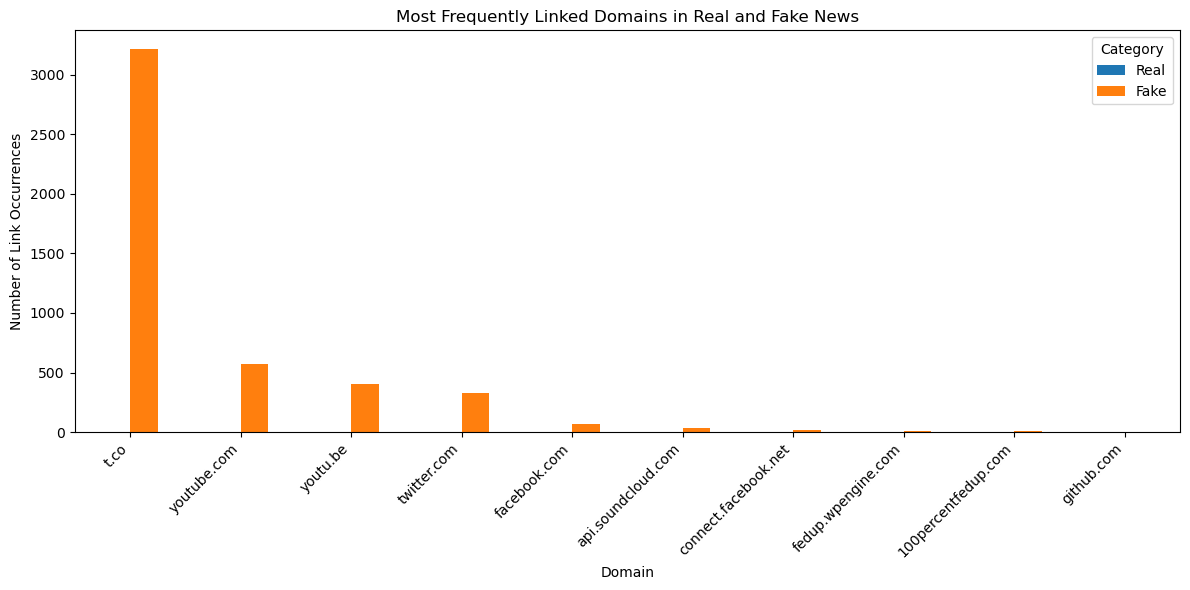

In [26]:
# the most common domains
top_domains = domain_frequency.head(10)

top_domains[["Real", "Fake"]].plot(kind="bar", figsize=(12, 6))

plt.title("Most Frequently Linked Domains in Real and Fake News")
plt.xlabel("Domain")
plt.ylabel("Number of Link Occurrences")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
# Identify domains shared across articles
domain_counts = domain_data.groupby("Domains").agg(
    Total_Mentions=("Domains", "count"),
    Articles_Linked=("Category", "size")
).sort_values("Total_Mentions", ascending=False)

domain_counts.head(15)

,Total_Mentions,Articles_Linked
Domains,,
t.co,3214,3214
youtube.com,572,572
youtu.be,405,405
twitter.com,331,331
facebook.com,68,68
api.soundcloud.com,30,30
connect.facebook.net,21,21
fedup.wpengine.com,12,12
100percentfedup.com,8,8


In [30]:
linked_articles = news[news["URL_Count"] > 0]

linked_articles[["Category", "title", "URLs", "Domains"]].head(10)

,Category,title,URLs,Domains
21419,Fake,Sheriff David Clarke Becomes An Internet Joke...,[https://t.co/zcbyc4Wp5b],[t.co]
21420,Fake,Trump Is So Obsessed He Even Has Obama’s Name...,"[https://t.co/Fg7VacxRtJ, https://t.co/zrWpyMX...","[t.co, t.co, t.co, t.co]"
21433,Fake,The Internet Brutally Mocks Disney’s New Trum...,"[https://t.co/XrOvu32EV8, https://t.co/HFYJRke...","[t.co, t.co, t.co]"
21436,Fake,Republican Senator Gets Dragged For Going Aft...,"[https://t.co/7lHYkIloyz, https://t.co/g8SwgAK...","[t.co, t.co, t.co]"
21444,Fake,WATCH: Fox Host Calls For A ‘Cleansing’ Of Th...,[https://t.co/SIoAxatCjp],[t.co]
21445,Fake,Liberal Group Trolls Trump At Roy Moore Rally...,[https://t.co/XpDJYFZjzn],[t.co]
21455,Fake,John McCain Wanted Another 74 Twitter Followe...,"[https://t.co/gWl6KsAaLE, https://t.co/TSb8B9O...","[t.co, t.co]"
21456,Fake,This Sarah Huckabee Sanders Tweet About Attac...,[https://t.co/SIoAxatCjp],[t.co]
21460,Fake,Trump Just Admitted He Knew Flynn Lied To The...,[https://t.co/c6Wtd0TfzW],[t.co]
21472,Fake,Sean Hannity Is Throwing A Stage-4 Temper Tan...,[https://t.co/6c0yV1lupe],[t.co]
